# Position Decoding

**Estimated time**: 20-25 minutes

**Prerequisites**: [02_spatial_rate_maps.ipynb](02_spatial_rate_maps.ipynb),
[05_simulation_and_validation.ipynb](05_simulation_and_validation.ipynb)

Fit spatial rate maps on a training block, decode a separate test block, and
report position error together with sampling support. The test trajectory is
used only for evaluation and plotting. This notebook runs independently and
needs no downloaded data.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from neurospatial.decoding import BayesianDecoder
from neurospatial.encoding import SpikeTrains
from neurospatial.simulation import linear_track_session

_here = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
if not (_here / "_style.py").exists():
    _here = _here / "examples"
if str(_here) not in sys.path:
    sys.path.insert(0, str(_here))
from _style import OKABE_ITO, apply_style

apply_style(figsize=(12, 4))
COLORS = {"blue": OKABE_ITO[0], "orange": OKABE_ITO[1], "cyan": OKABE_ITO[4]}

## Reserve a test block before fitting

A known 100 cm track avoids learning geometry from the test trajectory.
The session generator uses independent random streams for movement, field
placement and spikes. Repeated traversals expose the same locations in both
blocks, while the model's parameters remain stationary by construction.
For experiments, split by independent trials or sessions when appropriate;
adjacent samples randomly assigned to folds leak temporal information.

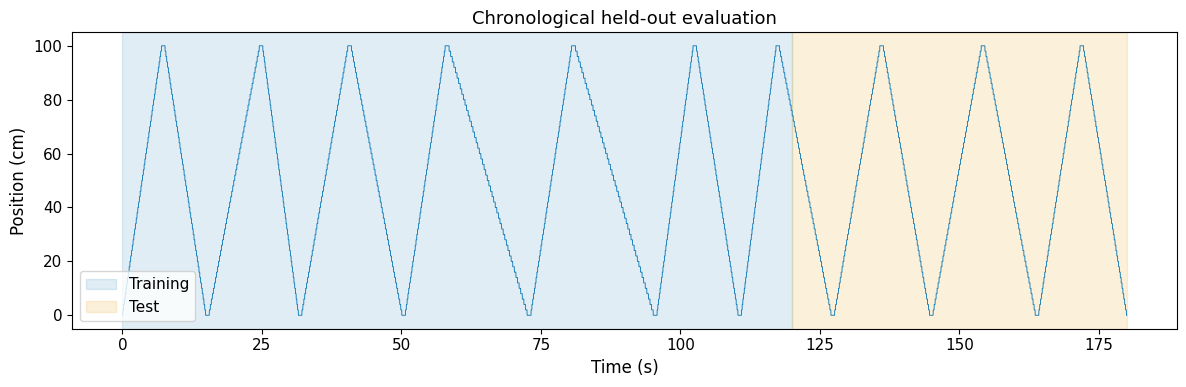

In [2]:
session = linear_track_session(
    duration=180.0,
    track_length=100.0,
    bin_size=2.0,
    n_place_cells=20,
    n_laps=20,
    seed=2026,
)
env, times, positions = session.env, session.times, session.positions
spikes = SpikeTrains(session.spike_times, unit_ids=100 + session.unit_ids)
train_epochs = (float(times[0]), 120.0)
test_epochs = (120.0, float(times[-1]))
recording_window = (float(times[0]), float(times[-1]))

fig, ax = plt.subplots()
ax.plot(times, positions[:, 0], lw=0.6)
ax.axvspan(*train_epochs, color=COLORS["blue"], alpha=0.12, label="Training")
ax.axvspan(*test_epochs, color=COLORS["orange"], alpha=0.15, label="Test")
ax.set(
    xlabel="Time (s)", ylabel="Position (cm)", title="Chronological held-out evaluation"
)
ax.legend()
fig.tight_layout()
plt.show()

## Fit, predict and score on distinct windows

Fix 100 ms decoding bins, 4 cm smoothing and a 0.5 s occupancy requirement
before examining test performance. `fit` returns a new immutable decoder;
assign that return value. Epochs and the spike-recording window are half-open
intervals in the original recording clock. Each fit uses training spikes and
training occupancy only; prediction receives spikes and timestamps, without
test positions. Both calls retain units that are silent in either block.

In [3]:
decoder = BayesianDecoder(
    env, dt=0.1, bandwidth=4.0, min_occupancy=0.5, max_gap=0.5
).fit(
    spikes,
    times,
    positions,
    epochs=train_epochs,
    spike_window=recording_window,
)
result = decoder.predict(
    spikes, times, epochs=test_epochs, spike_window=recording_window
)
test_median_error = decoder.score(
    spikes,
    times,
    positions,
    epochs=test_epochs,
    spike_window=recording_window,
    metric="median_error",
)
print(f"Held-out median MAP error: {test_median_error:.2f} cm (lower is better)")
print(f"Fitted unit labels: {decoder.unit_ids.tolist()}")
print(f"Posterior shape: {result.posterior.shape} (test time bins, spatial bins)")

Held-out median MAP error: 2.00 cm (lower is better)
Fitted unit labels: [100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119]
Posterior shape: (599, 51) (test time bins, spatial bins)


A list of arrays pairs units by list order. `SpikeTrains` carries explicit
labels, enabling the decoder to match labeled prediction inputs by identity.
Preserve the full fitted unit set, including empty spike trains. Missing a
unit is different from observing that unit fire zero times.

## Audit what the decoder could represent

Unobserved training locations stay outside `decoder.spatial_support`; no
zero-filling turns them into observed zero-rate locations. The posterior has
zero mass there. Good error on a small subset can hide missing coverage, so
report the support and the fraction of test bins with a finite posterior.
The physical-coordinate audit below uses this example's continuous tracking;
the official plotting and error APIs handle gaps in experimental inputs.

In [4]:
actual_positions = np.column_stack(
    [np.interp(result.times, times, positions[:, axis]) for axis in range(env.n_dims)]
)
actual_bins = env.bin_at(actual_positions)
truth_supported = np.zeros(result.n_time_bins, dtype=bool)
inside = actual_bins >= 0
truth_supported[inside] = decoder.spatial_support[actual_bins[inside]]
decodable = np.any(np.isfinite(result.posterior), axis=1)
errors = result.error_against(times, positions, max_gap=decoder.max_gap)
print(f"Training support: {decoder.spatial_support.sum()} / {env.n_bins} spatial bins")
print(f"Test truth inside training support: {truth_supported.mean():.1%}")
print(f"Finite posterior rows: {decodable.sum()} / {result.n_time_bins}")
print(f"Finite error rows: {np.isfinite(errors).sum()} / {result.n_time_bins}")
print(f"95th percentile MAP error: {np.nanpercentile(errors, 95):.2f} cm")
if np.any(~decoder.spatial_support):
    print(
        "Posterior mass outside support:",
        result.posterior[:, ~decoder.spatial_support].sum(),
    )

Training support: 51 / 51 spatial bins
Test truth inside training support: 100.0%
Finite posterior rows: 599 / 599
Finite error rows: 599 / 599
95th percentile MAP error: 98.00 cm


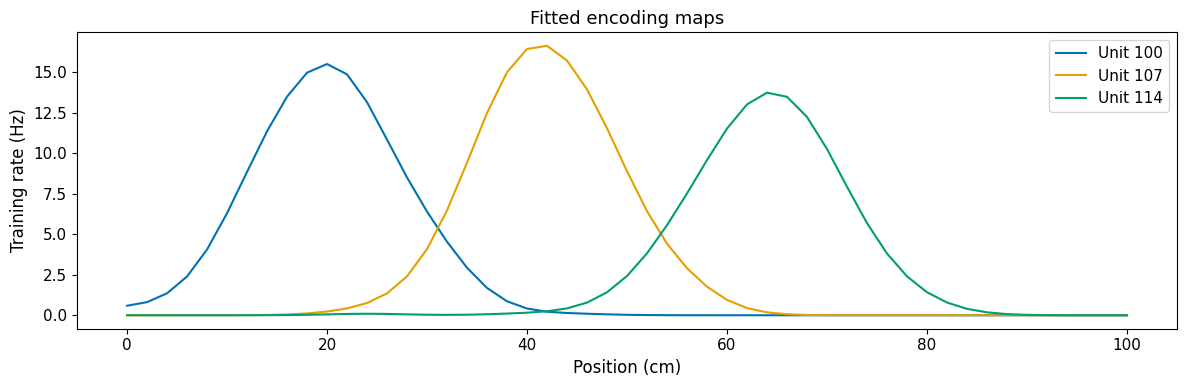

In [5]:
fig, ax = plt.subplots()
for unit_row in (0, 7, 14):
    ax.plot(
        env.bin_centers[:, 0],
        decoder.encoding_models[unit_row],
        label=f"Unit {decoder.unit_ids[unit_row]}",
    )
ax.set(
    xlabel="Position (cm)", ylabel="Training rate (Hz)", title="Fitted encoding maps"
)
ax.legend()
fig.tight_layout()
plt.show()

## Align a posterior overlay in spatial-bin coordinates

`result.plot` accepts actual positions in physical coordinates with their
original timestamps. It aligns tracking within observed runs, converts to
spatial-bin coordinates, and matches the image's time-axis convention.
No actual-position line is drawn across a dropout or outside tracked time.

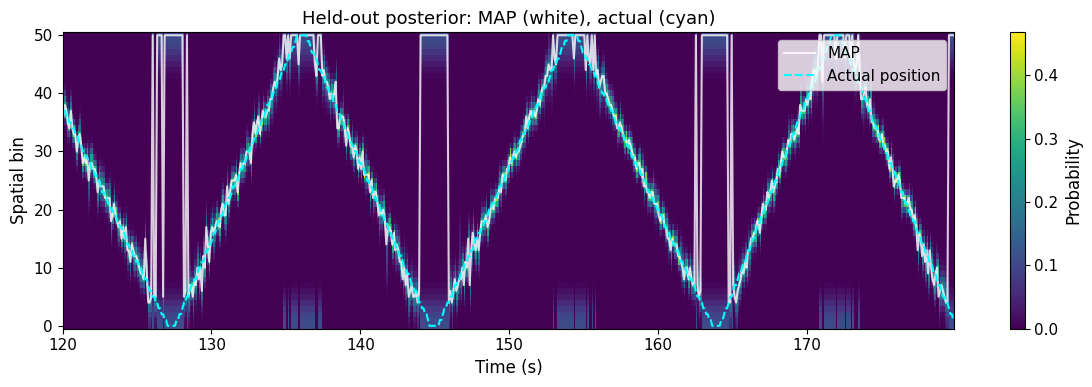

In [6]:
# Plot posterior rows and actual positions through the public overlay API.
fig, ax = plt.subplots(figsize=(12, 4))
result.plot(
    ax=ax,
    show_map=True,
    colorbar=True,
    true_times=times,
    true_positions=positions,
    max_gap=decoder.max_gap,
)
n_show = min(300, result.n_time_bins)
ax.set_title("Held-out posterior: MAP (white), actual (cyan)")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

For a gapped recording, the overlay and `error_against` share the same
`max_gap` rule for ground truth and leave unobserved times missing. `predict` forms
bins within observed runs and the requested windows, so no decoding bin spans
a gap. Physical position and error remain in cm, regardless of the heatmap's
bin-index axis. On a branching maze, use geodesic errors to respect barriers;
the mean of a multimodal posterior can fall between valid paths.
In this run the MAP occasionally jumps to the opposite end during pauses.
These errors expose ambiguous spike patterns under a decoder with no movement
prior. The simulated field centers lie in the track interior, leaving both
ends weakly coded; silent bins can favor the wrong end. Occupancy support
does not guarantee informative spikes. The median alone hides this tail.

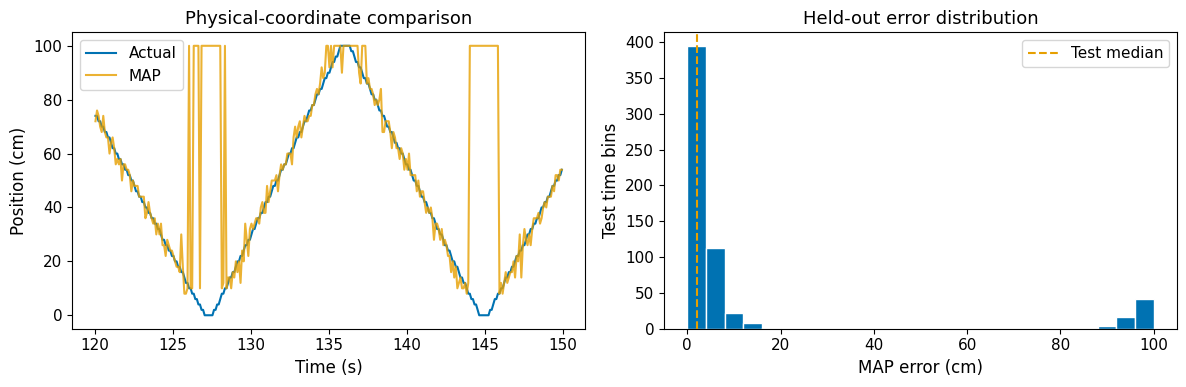

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(result.times[:n_show], actual_positions[:n_show, 0], label="Actual")
decoded_positions = result.map_position.copy()
decoded_positions[~decodable] = np.nan
axes[0].plot(
    result.times[:n_show],
    decoded_positions[:n_show, 0],
    color=COLORS["orange"],
    alpha=0.8,
    label="MAP",
)
axes[0].set(
    xlabel="Time (s)", ylabel="Position (cm)", title="Physical-coordinate comparison"
)
axes[0].legend()
finite_errors = errors[np.isfinite(errors)]
axes[1].hist(finite_errors, bins=25, edgecolor="white")
axes[1].axvline(test_median_error, color=COLORS["orange"], ls="--", label="Test median")
axes[1].set(
    xlabel="MAP error (cm)",
    ylabel="Test time bins",
    title="Held-out error distribution",
)
axes[1].legend()
fig.tight_layout()
plt.show()

## Interpret posterior uncertainty and choose the next analysis

Entropy summarizes uncertainty under the fitted model. It is not a calibrated
probability that a position estimate is correct. Correlated neurons, changing
tuning and the independent-Poisson likelihood can produce confident errors.
This stationary synthetic example cannot measure robustness to those effects.

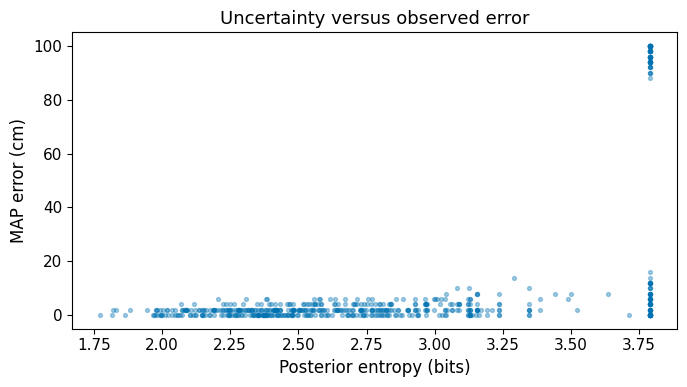

In [8]:
entropy = result.posterior_entropy
fig, ax = plt.subplots(figsize=(7, 4))
valid = np.isfinite(entropy) & np.isfinite(errors)
ax.scatter(entropy[valid], errors[valid], s=8, alpha=0.35)
ax.set(
    xlabel="Posterior entropy (bits)",
    ylabel="MAP error (cm)",
    title="Uncertainty versus observed error",
)
fig.tight_layout()
plt.show()

Select bandwidth, occupancy thresholds and decoding bin width using training
and separate validation blocks. Reserve the test block for the final error
report, and assess variability across independent trials or sessions rather
than treating autocorrelated decoding bins as independent replicates.

`decode_session` is convenient for reconstructing the data used to estimate
its own rate maps; its reconstruction error is in-sample. Use the split above
for generalization. `predict_summary` retains estimates and entropy without
storing a large posterior; `BayesianDecoder.from_rates` can reuse precomputed
population maps while preserving their support. See
[visualization](08_visualization.ipynb) for spatial animations of 2D posteriors.